# 03 — 검증 프레임 · anchor 재현 · 점수 정합성 확인

주최 측 베이스라인(`[Baseline_Train] RandomForest`)을 그대로 복제해서

1. **재현 검증** — 공식 노트북의 2019–2023 → 2024 검증 점수를 정확히 재현하는가
2. **점수 정합성** — 그 점수와 리더보드 549.51 의 격차가 얼마인가
   (= 2025 로 한 시즌 더 외삽하는 비용)
3. **오라클 분해** — 절편 / 기울기 / isotonic 을 완벽히 맞췄을 때의 상한.
   base rate 드리프트가 실제로 몇 점짜리인지 측정
4. **A/B/C/D 폴드** — 폴드마다 anchor 를 **재학습**해서 오염 없는 짝지은 Δ 계산
5. **실험 루프** — 2022 이전 F 제외 / 시간 감쇠 / game_type 별 절편 이동

앞선 노트북과 달리 여기서는 모델을 실제로 학습한다. RF 여러 번 학습에 수 분 걸린다.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.isotonic import IsotonicRegression

warnings.filterwarnings("ignore")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 80)

DATA_DIR = "/content/drive/MyDrive/lgaimers_9/data"
ART_DIR = "/content/drive/MyDrive/lgaimers_9/artifacts"
os.makedirs(ART_DIR, exist_ok=True)

ID = "row_id"
TARGET = "control_success"
CAT_COLS = ["top_bottom", "game_type", "base_state"]

LB_BASELINE = 549.51          # 주최 측 공지 베이스라인 리더보드 점수 (2025 test)

# 피처 목록은 test.csv 가 정한다 (공식 베이스라인과 동일 규칙)
test_cols = pd.read_csv(os.path.join(DATA_DIR, "test.csv"), encoding="utf-8-sig", nrows=0).columns
FEATURES = [c for c in test_cols if c != ID]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print(f"피처 {len(FEATURES)}개 (범주형 {len(CAT_COLS)}, 수치형 {len(NUM_COLS)})")

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), encoding="utf-8-sig",
                    usecols=list(dict.fromkeys(FEATURES + [TARGET, ID])))
print("train:", train.shape, "| 시즌", train.season.min(), "~", train.season.max())

피처 47개 (범주형 3, 수치형 44)
train: (1475092, 49) | 시즌 2019 ~ 2024


## 1. 채점 함수와 점수 환산

$$\text{Score} = \max\left(0,\ 10^5\left(1 - \frac{\mathrm{BS}}{r(1-r)}\right)\right)$$

폴드마다 $r$ 이 다르므로 **원시 Brier 는 폴드 간 비교 불가**다.
모든 결과를 리더보드 점수 환산으로 통일한다.
환산 계수는 $\partial\text{Score}/\partial\text{BS} = -10^5/(r(1-r))$.

In [3]:
def lb_score(y, p):
    y = np.asarray(y, dtype=np.float64); p = np.asarray(p, dtype=np.float64)
    r = y.mean(); denom = r * (1 - r)
    bs = np.mean((p - y) ** 2)
    return dict(score=max(0.0, 1e5 * (1 - bs / denom)), brier=bs, r=r,
                denom=denom, pts_per_1e4_bs=1e5 / denom * 1e-4)


def calib_report(y, p):
    # 절편(calibration-in-the-large), 기울기(Cox 1958), 오라클 재보정 상한
    y = np.asarray(y, float); p = np.asarray(p, float)
    r = y.mean(); denom = r * (1 - r)
    bias = p.mean() - y.mean()
    vp = p.var()
    b = (np.cov(y, p, bias=True)[0, 1] / vp) if vp > 0 else np.nan   # calibration slope
    a = y.mean() - b * p.mean()

    bs_raw = np.mean((p - y) ** 2)
    bs_mean = np.mean((p - bias - y) ** 2)                 # 절편만 완벽히
    bs_lin = np.mean((a + b * p - y) ** 2)                 # 선형 OLS = Brier 최적 선형족
    iso = IsotonicRegression(out_of_bounds="clip").fit(p, y)
    bs_iso = np.mean((iso.predict(p) - y) ** 2)

    to_pts = lambda bs: max(0.0, 1e5 * (1 - bs / denom))
    return dict(bias=bias, slope=b, alpha_star=1 - b, sd_pred=p.std(),
                score_raw=to_pts(bs_raw), score_mean_fixed=to_pts(bs_mean),
                score_linear=to_pts(bs_lin), score_isotonic=to_pts(bs_iso),
                gain_from_intercept=to_pts(bs_mean) - to_pts(bs_raw),
                gain_from_slope=to_pts(bs_lin) - to_pts(bs_mean),
                gain_from_isotonic=to_pts(bs_iso) - to_pts(bs_lin))

## 2. Anchor — 주최 측 베이스라인 정확 복제

공식 학습 노트북과 완전히 동일하게 구성한다.
`max_features` 는 지정되지 않았으므로 분류기 기본값 `'sqrt'` 가 쓰이며,
배포된 `rf.pkl` 을 열어 확인한 값과 일치한다.

In [4]:
def make_anchor():
    pre = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS),
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
    ])
    return Pipeline([
        ("pre", pre),
        ("clf", RandomForestClassifier(n_estimators=100, max_depth=10,
                                       min_samples_leaf=200, n_jobs=-1, random_state=42)),
    ])


def fit_predict(pipe, tr, va, sample_weight=None):
    t = time.time()
    if sample_weight is None:
        pipe.fit(tr[FEATURES], tr[TARGET])
    else:
        pipe.fit(tr[FEATURES], tr[TARGET], clf__sample_weight=sample_weight)
    p = pipe.predict_proba(va[FEATURES])[:, 1]
    return p, time.time() - t

## 3. 재현 검증 — 공식 노트북 §5 와 같은 값이 나오는가

공식 베이스라인은 **2019–2023 학습 → 2024 검증** 을 쓴다 (우리 fold D 와 동일).
`random_state=42` 고정, GPU 미사용이므로 같은 sklearn 버전이면 결정적이다.
공식 노트북을 직접 돌려 나온 `Validation Score` 와 아래 값이 일치해야 한다.

In [5]:
is_val = train["season"] == 2024
tr_D, va_D = train.loc[~is_val], train.loc[is_val]
print(f"train={len(tr_D):,}  val={len(va_D):,}")

anchor_D = make_anchor()
pD, secs = fit_predict(anchor_D, tr_D, va_D)
print(f"학습 {secs:.1f}s")

sD = lb_score(va_D[TARGET].values, pD)
print(f"\nBrier: {sD['brier']:.6f} | 기준선 r(1-r): {sD['denom']:.6f}")
print(f"Validation Score: {sD['score']:.2f}")
print(f"\n환산 계수: ΔBS 1e-4 = {sD['pts_per_1e4_bs']:.1f} 점")
print("\n※ 공식 [Baseline_Train] §5 출력과 이 값이 같아야 파이프라인 복제 성공")

train=1,221,585  val=253,507
학습 408.7s

Brier: 0.248769 | 기준선 r(1-r): 0.249807
Validation Score: 415.57

환산 계수: ΔBS 1e-4 = 40.0 점

※ 공식 [Baseline_Train] §5 출력과 이 값이 같아야 파이프라인 복제 성공


## 4. 점수 정합성 — 검증 점수 vs 리더보드 549.51

두 값은 **다른 대상**이라 같을 이유가 없다.

| | 학습 | 평가 |
|---|---|---|
| 우리 fold D | 2019–2023 (5시즌) | 2024 |
| 리더보드 549.51 | 2019–**2024** (6시즌, 전체 재학습) | **2025** |

리더보드 쪽이 학습 데이터가 한 시즌 더 많은데도 점수가 낮다면,
그 차이가 곧 **2025 로 한 시즌 더 외삽하는 비용**이다.
이 값이 앞으로 오프라인 개선폭을 해석하는 기준이 된다.

In [6]:
gap = sD["score"] - LB_BASELINE
print(f"fold D  (2019-23 -> 2024) : {sD['score']:8.2f}")
print(f"리더보드 (2019-24 -> 2025) : {LB_BASELINE:8.2f}")
print(f"격차                      : {gap:+8.2f} 점")
print()
if gap > 0:
    print(f"-> 2024 검증이 약 {gap:.0f}점 낙관적.")
    print(f"   오프라인 +X점 개선이 리더보드에서는 대략 x{LB_BASELINE/sD['score']:.2f} 로 축소될 수 있다.")
else:
    print("-> 2024 검증이 오히려 보수적. 2025 가 더 예측하기 쉬웠다는 뜻.")

# 전체 재학습 — 배포된 rf.pkl 과 동일 구성인지 대조
full_anchor = make_anchor()
full_anchor.fit(train[FEATURES], train[TARGET])
test5 = pd.read_csv(os.path.join(DATA_DIR, "test.csv"), encoding="utf-8-sig")
p5 = full_anchor.predict_proba(test5[FEATURES])[:, 1]
print("\n전체 재학습 완료. test 5행 예측:", np.round(p5, 5))

# 배포 pkl 이 손에 있으면 직접 대조 (선택)
try:
    import joblib
    ref = joblib.load("./model/rf.pkl")
    p5_ref = ref.predict_proba(test5[FEATURES])[:, 1]
    print("배포 rf.pkl 예측 :", np.round(p5_ref, 5))
    print("최대 차이        :", float(np.abs(p5 - p5_ref).max()))
except Exception as e:
    print("(배포 rf.pkl 대조 생략:", e, ")")

fold D  (2019-23 -> 2024) :   415.57
리더보드 (2019-24 -> 2025) :   549.51
격차                      :  -133.94 점

-> 2024 검증이 오히려 보수적. 2025 가 더 예측하기 쉬웠다는 뜻.

전체 재학습 완료. test 5행 예측: [0.46291 0.44757 0.48513 0.50627 0.48981]
(배포 rf.pkl 대조 생략: [Errno 2] No such file or directory: './model/rf.pkl' )


## 5. 오라클 분해 — 헤드룸이 어디에 있는가

검증 정답을 써서 **완벽하게** 재보정했을 때의 점수를 구한다.
실제로 쓸 수 있는 값은 아니지만, 각 오차원의 크기를 재는 자다.

- `score_mean_fixed` : 평균만 정확히 → **base rate 드리프트 비용**
- `score_linear`     : $a+bp$ OLS → Brier 최적 선형족 (Platt 아님, L2 최적)
- `score_isotonic`   : 비모수 단조 상한

`slope` $b<1$ 이면 과신(축소 필요), $b>1$ 이면 과소신(**확장** 필요).
주최 측 RF 는 강하게 정규화돼 있어 $b>1$ 이 나올 수 있다.

In [7]:
rep = calib_report(va_D[TARGET].values, pD)
print(f"예측 평균 {pD.mean():.5f} / 실제 {va_D[TARGET].mean():.5f} / 편향 {rep['bias']:+.5f}")
print(f"예측 표준편차 {rep['sd_pred']:.5f}   (BSS 상한 = Var(p)/r(1-r) = {pD.var()/sD['denom']:.5f})")
print(f"calibration slope b = {rep['slope']:.4f}   (alpha* = {rep['alpha_star']:+.4f})")
print()
print(f"{'raw':24s} {rep['score_raw']:9.2f}")
print(f"{'+ 절편 완벽':24s} {rep['score_mean_fixed']:9.2f}   (+{rep['gain_from_intercept']:.2f})")
print(f"{'+ 선형 OLS':24s} {rep['score_linear']:9.2f}   (+{rep['gain_from_slope']:.2f})")
print(f"{'+ isotonic':24s} {rep['score_isotonic']:9.2f}   (+{rep['gain_from_isotonic']:.2f})")
print()
print("※ 절편 이득이 크면 2025 base rate 예측이 최우선 과제")
print("※ isotonic 이 선형 대비 거의 안 늘면 선형 재보정으로 충분")

예측 평균 0.50120 / 실제 0.48610 / 편향 +0.01509
예측 표준편차 0.03244   (BSS 상한 = Var(p)/r(1-r) = 0.00421)
calibration slope b = 1.1014   (alpha* = -0.1014)

raw                         415.57
+ 절편 완벽                     506.78   (+91.21)
+ 선형 OLS                    511.11   (+4.33)
+ isotonic                  552.87   (+41.76)

※ 절편 이득이 크면 2025 base rate 예측이 최우선 과제
※ isotonic 이 선형 대비 거의 안 늘면 선형 재보정으로 충분


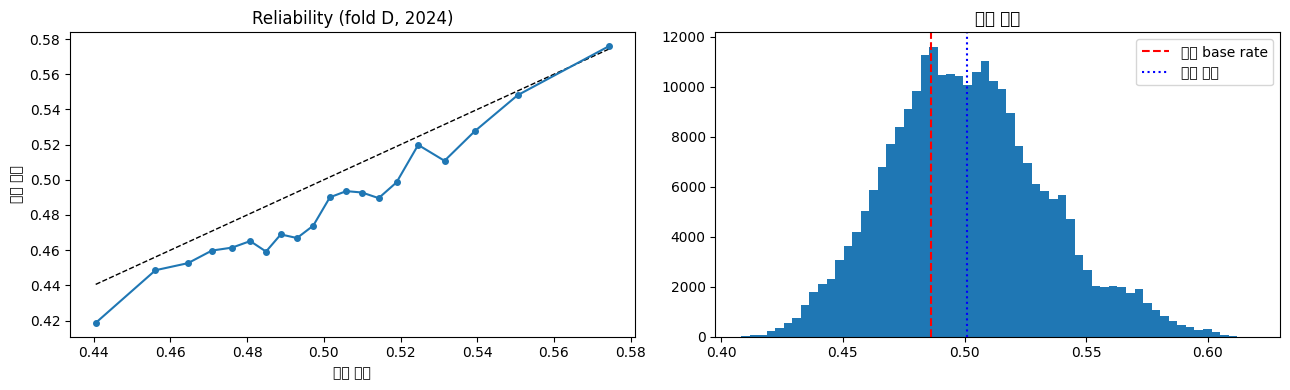

         n  p_mean  y_mean
bin                       
0    12676  0.4405  0.4187
1    12675  0.4561  0.4486
2    12675  0.4646  0.4526
3    12676  0.4708  0.4598
4    12675  0.4761  0.4615
5    12675  0.4808  0.4652
6    12676  0.4849  0.4592
7    12675  0.4888  0.4690
8    12675  0.4930  0.4669
9    12675  0.4973  0.4739
10   12676  0.5016  0.4901
11   12673  0.5059  0.4936
12   12677  0.5100  0.4928
13   12676  0.5143  0.4896
14   12675  0.5190  0.4985
15   12675  0.5246  0.5198
16   12676  0.5315  0.5108
17   12675  0.5393  0.5276
18   12675  0.5505  0.5481
19   12676  0.5743  0.5760


In [8]:
# 신뢰도 곡선 — 어느 구간에서 어긋나는지
edges = np.unique(np.quantile(pD, np.linspace(0, 1, 21)))
idx = np.clip(np.digitize(pD, edges[1:-1]), 0, len(edges) - 2)
cal = pd.DataFrame({"bin": idx, "p": pD, "y": va_D[TARGET].values})
g = cal.groupby("bin").agg(n=("y", "size"), p_mean=("p", "mean"), y_mean=("y", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lo, hi = g.p_mean.min(), g.p_mean.max()
ax[0].plot([lo, hi], [lo, hi], "k--", lw=1)
ax[0].plot(g.p_mean, g.y_mean, "o-", ms=4)
ax[0].set_xlabel("예측 확률"); ax[0].set_ylabel("실제 비율")
ax[0].set_title("Reliability (fold D, 2024)")
ax[1].hist(pD, bins=60)
ax[1].axvline(va_D[TARGET].mean(), color="r", ls="--", label="실제 base rate")
ax[1].axvline(pD.mean(), color="b", ls=":", label="예측 평균")
ax[1].legend(); ax[1].set_title("예측 분포")
plt.tight_layout(); plt.show()
print(g.round(4).to_string())

## 6. 폴드 정의 — anchor 는 폴드마다 재학습

배포된 `rf.pkl` 은 2019–2024 **전체**로 학습돼 fold A/B/C 의 검증 시즌을 이미 봤다.
그걸 anchor 로 쓰면 Δ 가 체계적으로 왜곡되고, 폴드마다 오염 정도도 달라
폴드 간 비교가 무의미해진다. 따라서 **각 폴드의 학습 구간으로 anchor 를 다시 적합**한다.

| fold | train | valid | 용도 |
|---|---|---|---|
| A | 2019–2021 | 2022 | 모델 선택 |
| B | 2020–2022 | 2023 | 모델 선택 |
| C | 2021–2023 | 2024 | 모델 선택 + **드리프트 대응 주근거** |
| D | 2019–2023 | 2024 | **최종 확인 전용 (재튜닝 금지)** |

A/B/C 는 학습 창이 3시즌으로 동일해 조건이 같다.
D 는 실제 대회의 분포 이동 폭과 가장 가까워 fidelity fold 역할을 한다.

In [9]:
FOLDS = {
    "A": (list(range(2019, 2022)), 2022),
    "B": (list(range(2020, 2023)), 2023),
    "C": (list(range(2021, 2024)), 2024),
    "D": (list(range(2019, 2024)), 2024),
}

anchor_preds, fold_meta = {}, {}
for name, (tr_seasons, va_season) in FOLDS.items():
    tr = train[train.season.isin(tr_seasons)]
    va = train[train.season == va_season]
    p, secs = fit_predict(make_anchor(), tr, va)
    sc = lb_score(va[TARGET].values, p)
    anchor_preds[name] = p
    fold_meta[name] = dict(va_idx=va.index, r=sc["r"], denom=sc["denom"],
                           score=sc["score"], n_tr=len(tr), n_va=len(va),
                           r_tr=float(tr[TARGET].mean()))
    print(f"[{name}] {tr_seasons[0]}-{tr_seasons[-1]} ({len(tr):>9,}) -> {va_season} ({len(va):>7,})  "
          f"r_tr={tr[TARGET].mean():.4f} r_va={sc['r']:.4f} shift={sc['r']-tr[TARGET].mean():+.4f}  "
          f"anchor={sc['score']:8.2f}  ({secs:.0f}s)")

np.savez(os.path.join(ART_DIR, "anchor_preds.npz"), **anchor_preds)

[A] 2019-2021 (  728,588) -> 2022 (247,472)  r_tr=0.5431 r_va=0.5289 shift=-0.0142  anchor= 2077.49  (223s)
[B] 2020-2022 (  738,647) -> 2023 (245,525)  r_tr=0.5315 r_va=0.5000 shift=-0.0315  anchor=    0.00  (229s)
[C] 2021-2023 (  740,085) -> 2024 (253,507)  r_tr=0.5206 r_va=0.4861 shift=-0.0345  anchor=  420.48  (232s)
[D] 2019-2023 (1,221,585) -> 2024 (253,507)  r_tr=0.5316 r_va=0.4861 shift=-0.0455  anchor=  415.57  (378s)


In [10]:
# 폴드별 anchor 캘리브레이션 진단 — 정규화 방향의 지표
rows = []
for name in FOLDS:
    va = train.loc[fold_meta[name]["va_idx"]]
    rp = calib_report(va[TARGET].values, anchor_preds[name])
    rows.append({"fold": name, "r_val": fold_meta[name]["r"], "score": rp["score_raw"],
                 "bias": rp["bias"], "slope": rp["slope"], "sd_pred": rp["sd_pred"],
                 "d_intercept": rp["gain_from_intercept"], "d_slope": rp["gain_from_slope"],
                 "d_isotonic": rp["gain_from_isotonic"]})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\nd_intercept 가 폴드마다 크면 base rate 이동이 지배적 오차원")

fold  r_val     score   bias  slope  sd_pred  d_intercept  d_slope  d_isotonic
   A 0.5289 2077.4896 0.0014 1.2313   0.0595       0.7812  76.0392     69.5658
   B 0.5000    0.0000 0.0196 0.2622   0.0536       0.0000  79.0736    301.1724
   C 0.4861  420.4815 0.0148 1.1063   0.0324      87.9995   4.7388     37.9566
   D 0.4861  415.5738 0.0151 1.1014   0.0324      91.2082   4.3304     41.7576

d_intercept 가 폴드마다 크면 base rate 이동이 지배적 오차원


## 7. 짝지은 Δ + 투수 단위 클러스터 부트스트랩

$$\delta_i = (p_i^{\text{cand}}-y_i)^2 - (p_i^{\text{anchor}}-y_i)^2$$

같은 행에서의 차이라 폴드 난이도가 상쇄된다. 리더보드 점수로 환산해
**양수가 개선**이 되도록 부호를 뒤집는다.

행 단위 i.i.d. 표준오차는 낙관적이다 — 같은 투수의 투구는 강하게 상관된다.
경기 식별자가 데이터에 없으므로 **투수 단위 클러스터**로 리샘플한다
(모델의 계통 편향이 투수 단위로 발생하므로 이게 지배적 상관원이다).

In [11]:
def cluster_bootstrap_delta(delta, cluster, n_boot=1000, seed=0):
    codes, uniq = pd.factorize(np.asarray(cluster))
    s = np.bincount(codes, weights=delta)
    n = np.bincount(codes).astype(float)
    K = len(uniq)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, K, size=(n_boot, K))
    return s[idx].sum(1) / n[idx].sum(1)


def evaluate(cand_preds, label, n_boot=1000):
    rows = []
    for name in FOLDS:
        if name not in cand_preds:
            continue
        va = train.loc[fold_meta[name]["va_idx"]]
        y = va[TARGET].values.astype(float)
        pc, pa = np.asarray(cand_preds[name], float), anchor_preds[name]
        d = (pc - y) ** 2 - (pa - y) ** 2
        to_pts = -1e5 / fold_meta[name]["denom"]      # ΔBS -> 점수 (음수 Δ = 양수 점수)
        boot = cluster_bootstrap_delta(d, va["pitcher_id"].values, n_boot=n_boot) * to_pts
        lo, hi = np.quantile(boot, [0.025, 0.975])
        rows.append({"fold": name, "label": label,
                     "score": lb_score(y, pc)["score"], "anchor": fold_meta[name]["score"],
                     "delta_pts": d.mean() * to_pts,
                     "ci_lo": min(lo, hi), "ci_hi": max(lo, hi),
                     "slope": calib_report(y, pc)["slope"]})
    out = pd.DataFrame(rows)
    if len(out):
        sg = np.sign(out["delta_pts"])
        out.attrs["consistent"] = bool((sg == sg.iloc[0]).all())
    return out


# 자기 자신 대조 — Δ 가 정확히 0 이어야 한다 (구현 검증)
chk = evaluate({k: anchor_preds[k] for k in FOLDS}, "anchor(self-check)", n_boot=200)
print(chk.round(4).to_string(index=False))
assert np.allclose(chk["delta_pts"], 0), "Δ 구현 오류"
print("\n✅ Δ 구현 검증 통과")

fold              label     score    anchor  delta_pts  ci_lo  ci_hi  slope
   A anchor(self-check) 2077.4896 2077.4896       -0.0   -0.0   -0.0 1.2313
   B anchor(self-check)    0.0000    0.0000       -0.0   -0.0   -0.0 0.2622
   C anchor(self-check)  420.4815  420.4815       -0.0   -0.0   -0.0 1.1063
   D anchor(self-check)  415.5738  415.5738       -0.0   -0.0   -0.0 1.1014

✅ Δ 구현 검증 통과


## 8. 층화 진단

전체 평균 하나로는 "특정 구간에서만 좋아진 모델"을 걸러낼 수 없다.
- `asof_pitcher_n` 구간 (표본 축적도)
- 볼카운트 상태 (제구 전략이 다름)
- `game_type` (R/F 레짐)
- `pitcher_team_id == 13` (2군 오염 집단)
- 월 (시즌 진행률)

In [12]:
def stratified_delta(cand_preds, fold="C"):
    va = train.loc[fold_meta[fold]["va_idx"]].copy()
    y = va[TARGET].values.astype(float)
    d = (np.asarray(cand_preds[fold], float) - y) ** 2 - (anchor_preds[fold] - y) ** 2
    to_pts = -1e5 / fold_meta[fold]["denom"]
    va["_d"] = d
    va["_nbin"] = pd.cut(va["asof_pitcher_n"], [-1, 0, 50, 200, 1000, 5000, np.inf],
                         labels=["0", "1-50", "51-200", "201-1k", "1k-5k", "5k+"])
    va["_count"] = va["balls_before"].astype(str) + "-" + va["strikes_before"].astype(str)
    va["_team13"] = va["pitcher_team_id"] == 13

    for axis in ["_nbin", "_count", "game_type", "_team13", "game_month"]:
        t = va.groupby(axis, observed=True).agg(n=("_d", "size"), delta=("_d", "mean"))
        t["delta_pts"] = (t["delta"] * to_pts).round(2)
        t["pct"] = (t["n"] / len(va) * 100).round(2)
        print(f"--- {axis} (fold {fold}) ---")
        print(t[["n", "pct", "delta_pts"]].sort_values("delta_pts").to_string())
        print()

## 9. 실험 루프 — 학습 데이터 구성

노트북 01–02 에서 나온 두 가지를 검증한다.

- **2022 이전 F 제외** (105,308행, 7.1%) — reverse 성분이 과소기록된 구간
- **시간 감쇠** $w_t = e^{-\lambda \Delta t}$

fold A 는 오염 구간이 아직 유효하므로 F 제외 판단의 근거가 못 된다.
**fold C 를 주근거**로 보고 D 는 손대지 않는다.

In [13]:
def run_variant(drop_pre2023_F=False, decay_lambda=None, folds=("A", "B", "C")):
    preds = {}
    for name in folds:
        tr_seasons, va_season = FOLDS[name]
        tr = train[train.season.isin(tr_seasons)]
        if drop_pre2023_F:
            tr = tr[~((tr.game_type == "F") & (tr.season <= 2022))]
        w = None
        if decay_lambda is not None:
            w = np.exp(-decay_lambda * (va_season - tr["season"].values))
        va = train[train.season == va_season]
        p, _ = fit_predict(make_anchor(), tr, va, sample_weight=w)
        preds[name] = p
    return preds


variants = [
    ("baseline(all)", dict()),
    ("drop pre2023 F", dict(drop_pre2023_F=True)),
    ("decay 0.15", dict(decay_lambda=0.15)),
    ("decay 0.30", dict(decay_lambda=0.30)),
    ("dropF + decay0.15", dict(drop_pre2023_F=True, decay_lambda=0.15)),
]

results, variant_preds = [], {}
for label, kw in variants:
    t = time.time()
    pr = run_variant(**kw)
    variant_preds[label] = pr
    res = evaluate(pr, label)
    results.append(res)
    print(f"=== {label}  ({time.time()-t:.0f}s) ===")
    print(res.round(3).to_string(index=False))
    print(f"부호 일관성: {res.attrs.get('consistent')}\n")

ALL = pd.concat(results, ignore_index=True)
print(ALL.pivot(index="label", columns="fold", values="delta_pts").round(2).to_string())

=== baseline(all)  (663s) ===
fold         label    score   anchor  delta_pts  ci_lo  ci_hi  slope
   A baseline(all) 2077.490 2077.490        0.0   -0.0    0.0  1.231
   B baseline(all)    0.000    0.000        0.0   -0.0    0.0  0.262
   C baseline(all)  420.481  420.481        0.0   -0.0    0.0  1.106
부호 일관성: True

=== drop pre2023 F  (597s) ===
fold          label   score   anchor  delta_pts     ci_lo     ci_hi  slope
   A drop pre2023 F 738.276 2077.490  -1339.214 -1650.629 -1064.699  1.447
   B drop pre2023 F 545.499    0.000   1246.944   940.062  1588.723  1.141
   C drop pre2023 F 532.272  420.481    111.790    71.762   160.869  1.111
부호 일관성: False

=== decay 0.15  (666s) ===
fold      label    score   anchor  delta_pts   ci_lo  ci_hi  slope
   A decay 0.15 2072.259 2077.490     -5.231 -22.197 12.027  1.194
   B decay 0.15    0.000    0.000      0.228 -23.795 22.041  0.261
   C decay 0.15  453.936  420.481     33.454  16.696 50.682  1.128
부호 일관성: False

=== decay 0.30  (663s) =

In [14]:
# game_type 별 절편 이동 — 학습 시즌 추세를 외삽해 상수로 고정 (test 평균 참조 금지)
def fit_intercept_shift(tr_seasons, target_season):
    shifts = {}
    for gt, sub in train[train.season.isin(tr_seasons)].groupby("game_type"):
        s = sub.groupby("season")[TARGET].mean()
        if len(s) >= 2:
            b, a = np.polyfit(s.index.values.astype(float), s.values, 1)
            shifts[gt] = float(a + b * target_season)
        else:
            shifts[gt] = float(s.mean())
    return shifts


def apply_shift(p, va, shifts, damp):
    out = np.asarray(p, float).copy()
    for gt, tgt in shifts.items():
        m = (va["game_type"] == gt).values
        if m.sum() == 0:
            continue
        out[m] = np.clip(out[m] + damp * (tgt - out[m].mean()), 1e-6, 1 - 1e-6)
    return out


print(f"{'damp':>6} " + "  ".join(f"{f:>10}" for f in ["A", "B", "C"]))
for damp in [0.0, 0.25, 0.5, 0.75, 1.0]:
    shifted = {}
    for name in ["A", "B", "C"]:
        tr_seasons, va_season = FOLDS[name]
        va = train[train.season == va_season]
        shifted[name] = apply_shift(anchor_preds[name], va,
                                    fit_intercept_shift(tr_seasons, va_season), damp)
    r = evaluate(shifted, f"intercept damp={damp}", n_boot=300)
    print(f"{damp:>6} " + "  ".join(f"{row.delta_pts:>+10.1f}" for row in r.itertuples()))
print("\n※ damp=1.0 은 학습 추세 외삽값으로 예측 평균을 완전히 이동")

  damp          A           B           C
   0.0       -0.0        -0.0        -0.0
  0.25      +25.7      -565.3      +102.6
   0.5      +36.2     -1243.1      +130.0
  0.75      +31.7     -2033.4       +82.0
   1.0      +12.1     -2936.3       -41.2

※ damp=1.0 은 학습 추세 외삽값으로 예측 평균을 완전히 이동


## 10. 요약

`d_intercept` 가 다른 이득을 압도하면 2025 base rate 예측이 최우선 과제다.
Δ 의 부호가 A/B/C 에서 일관되지 않는 변형은 채택하지 않는다.
fold D 는 §3–5 의 재현·정합성 확인 외에는 열지 않는다.

In [15]:
print("=" * 80)
print(f"1) 재현       : fold D anchor score = {fold_meta['D']['score']:.2f}")
print(f"               공식 [Baseline_Train] §5 출력과 일치해야 함")
print(f"\n2) 정합성     : fold D {fold_meta['D']['score']:.2f}  vs  리더보드 {LB_BASELINE:.2f}"
      f"  = {fold_meta['D']['score']-LB_BASELINE:+.2f} 점")
print(f"\n3) 오라클 헤드룸 (fold D)")
print(f"   절편만 완벽   +{rep['gain_from_intercept']:8.1f} 점")
print(f"   + 선형 재보정 +{rep['gain_from_slope']:8.1f} 점")
print(f"   + isotonic    +{rep['gain_from_isotonic']:8.1f} 점")
print(f"   calibration slope b = {rep['slope']:.4f}")
print(f"\n4) 변형별 Δ (리더보드 점수 환산, 양수 = 개선)")
print(ALL.pivot(index="label", columns="fold", values="delta_pts").round(2).to_string())
print("=" * 80)

1) 재현       : fold D anchor score = 415.57
               공식 [Baseline_Train] §5 출력과 일치해야 함

2) 정합성     : fold D 415.57  vs  리더보드 549.51  = -133.94 점

3) 오라클 헤드룸 (fold D)
   절편만 완벽   +    91.2 점
   + 선형 재보정 +     4.3 점
   + isotonic    +    41.8 점
   calibration slope b = 1.1014

4) 변형별 Δ (리더보드 점수 환산, 양수 = 개선)
fold                     A        B       C
label                                      
baseline(all)         0.00     0.00    0.00
decay 0.15           -5.23     0.23   33.45
decay 0.30            8.69    -4.41   29.60
drop pre2023 F    -1339.21  1246.94  111.79
dropF + decay0.15 -1363.06  1228.86  116.82


In [16]:
# anchor 재정의 — 오염 제거를 기본값으로
def clean_train(df):
    return df[~((df.game_type == "F") & (df.season <= 2022))]

anchor_preds, fold_meta = {}, {}
for name, (tr_seasons, va_season) in FOLDS.items():
    tr = clean_train(train[train.season.isin(tr_seasons)])
    va = train[train.season == va_season]
    p, secs = fit_predict(make_anchor(), tr, va)
    m = (va.game_type == "R").values            # ← R 전용 평가
    sc = lb_score(va[TARGET].values[m], p[m])
    anchor_preds[name] = p
    fold_meta[name] = dict(va_idx=va.index, eval_mask=m, r=sc["r"],
                           denom=sc["denom"], score=sc["score"])
    scF = lb_score(va[TARGET].values[~m], p[~m]) if (~m).sum() else None
    print(f"[{name}] R-only score={sc['score']:8.2f}"
          + (f"  | F-only={scF['score']:8.2f} (n={(~m).sum():,})" if scF else ""))

[A] R-only score=  469.49  | F-only=    0.00 (n=30,448)
[B] R-only score=  580.84  | F-only=    0.00 (n=25,686)
[C] R-only score=  553.24  | F-only=   48.23 (n=30,010)
[D] R-only score=  575.83  | F-only=   38.97 (n=30,010)


In [17]:
# 정직한 isotonic 이득: 절반 적합 / 절반 평가
from sklearn.isotonic import IsotonicRegression
rng = np.random.default_rng(0)
h = rng.random(len(pD)) < 0.5
yD = va_D[TARGET].values.astype(float)
den = lb_score(yD, pD)["denom"]

iso = IsotonicRegression(out_of_bounds="clip").fit(pD[h], yD[h])
b_, a_ = np.polyfit(pD[h], yD[h], 1)
to_pts = lambda p, y: max(0., 1e5 * (1 - np.mean((p - y) ** 2) / den))

print("블록 수:", len(np.unique(iso.predict(pD))))
print("held-out raw     :", round(to_pts(pD[~h], yD[~h]), 2))
print("held-out linear  :", round(to_pts(a_ + b_ * pD[~h], yD[~h]), 2))
print("held-out isotonic:", round(to_pts(iso.predict(pD[~h]), yD[~h]), 2))

블록 수: 79
held-out raw     : 376.77
held-out linear  : 457.5
held-out isotonic: 444.08


In [18]:
from google.colab import runtime
runtime.unassign()